In [ ]:
import os
import time

import numpy as np
import tensorflow as tf
import keras
from keras.applications import MobileNetV2
from keras.applications.mobilenet_v2 import preprocess_input
import matplotlib.pyplot as plt
from PIL import Image
from PIL import ImageFilter
from keras.layers import Input, GlobalAveragePooling2D
from keras.models import Model
import urllib.request
from urllib.parse import quote

import warnings
warnings.filterwarnings("ignore")

# Task one

In [ ]:
category = [
    "cat", "dog",
    "sun", "smiley face", "moon",
    "cup", "bucket",
    "apple", "tree", "house",
    "car", "bicycle", "clock",
    "flower", "fish",
]

heldout = ["cell phone", "envelope"]

RAW_DIR = "data/raw"
OUT_PATH = "data/subset.npz"
URL = "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/{}.npy"

os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs("data", exist_ok=True)

In [ ]:
def download_category(name):
    path = os.path.join(RAW_DIR, f"{name}.npy")
    if os.path.exists(path):
        print(f"already have {name}")
        return path
    print(f"downloading {name} ...")
    urllib.request.urlretrieve(URL.format(quote(name)), path)
    return path

for name in category + heldout:
    download_category(name)

downloading cat ...
downloading dog ...
downloading sun ...
downloading smiley face ...
downloading moon ...
downloading cup ...
downloading bucket ...
downloading apple ...
downloading tree ...
downloading house ...
downloading car ...
downloading bicycle ...
downloading clock ...
downloading flower ...
downloading fish ...
downloading cell phone ...
downloading envelope ...


In [ ]:
rng = np.random.default_rng(42)

def sample_category(name, n):
    arr = np.load(os.path.join(RAW_DIR, f"{name}.npy"), mmap_mode="r")
    idx = np.sort(rng.choice(len(arr), size=n, replace=False))
    return np.array(arr[idx]).reshape(-1, 28, 28).astype("uint8")

samples = {name: sample_category(name, 500) for name in category}
heldout_samples = {name: sample_category(name, 50) for name in heldout}

In [ ]:
gallery_images, gallery_labels = [], []
query_images, query_labels = [], []

for label, name in enumerate(category):
    imgs = samples[name]
    gallery_images.append(imgs[:450])
    gallery_labels += [label] * 450
    query_images.append(imgs[450:])
    query_labels += [label] * 50

heldout_images, heldout_labels = [], []
for i, name in enumerate(heldout):
    heldout_images.append(heldout_samples[name])
    heldout_labels += [i] * 50

gallery_images = np.concatenate(gallery_images)
gallery_labels = np.array(gallery_labels)
query_images = np.concatenate(query_images)
query_labels = np.array(query_labels)
heldout_images = np.concatenate(heldout_images)
heldout_labels = np.array(heldout_labels)

print("gallery :", gallery_images.shape)
print("queries :", query_images.shape)
print("held-out:", heldout_images.shape)

gallery : (6750, 28, 28)
queries : (750, 28, 28)
held-out: (100, 28, 28)


In [ ]:
np.savez_compressed(
    OUT_PATH,
    gallery_images=gallery_images,
    gallery_labels=gallery_labels,
    query_images=query_images,
    query_labels=query_labels,
    heldout_images=heldout_images,
    heldout_labels=heldout_labels,
    category=np.array(category),
    heldout=np.array(heldout),
)

print("saved", OUT_PATH)

saved data/subset.npz


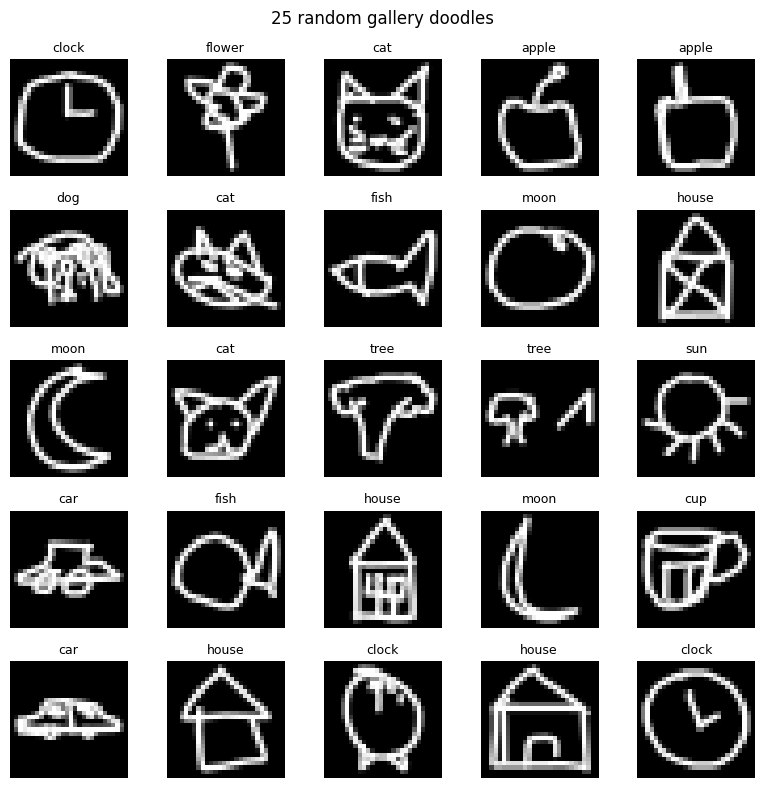

In [ ]:
data = np.load(OUT_PATH)
names = data["category"]

plot_rng = np.random.default_rng(0)
picks = plot_rng.choice(len(data["gallery_images"]), size=25, replace=False)

fig, axes = plt.subplots(5, 5, figsize=(8, 8))
for ax, i in zip(axes.ravel(), picks):
    ax.imshow(data["gallery_images"][i], cmap="gray")
    ax.set_title(names[data["gallery_labels"][i]], fontsize=9)
    ax.axis("off")
plt.suptitle("25 random gallery doodles")
plt.tight_layout()
plt.show()

# Task two

In [ ]:
backbone = MobileNetV2(
    input_shape=(160, 160, 3),
    include_top=False,
    weights="imagenet"
)

backbone.trainable = False

inputs = Input(shape=(160, 160, 3))
x = backbone(inputs)
outputs = GlobalAveragePooling2D()(x)

model = Model(inputs=inputs, outputs=outputs)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
def to_model_input(images_28, invert=False):

    images = np.array(images_28, dtype="float32")

    if invert:
        images = 255.0 - images

    images = np.expand_dims(images, axis=-1)

    images = tf.image.resize(images, (160, 160)).numpy()

    images = np.repeat(images, 3, axis=-1)

    images = preprocess_input(images)

    return images

In [ ]:
test_images = to_model_input(data["gallery_images"][:5])

print("Image shape:", test_images.shape)
print("Minimum value:", test_images.min())
print("Maximum value:", test_images.max())

Image shape: (5, 160, 160, 3)
Minimum value: -1.0
Maximum value: 1.0


In [ ]:
def embed(model, images_28, invert=False, batch_size=64):

    features = []

    for i in range(0, len(images_28), batch_size):

        batch = images_28[i:i + batch_size]

        batch = to_model_input(batch, invert=invert)

        predictions = model.predict(batch, verbose=0)

        features.append(predictions)

    features = np.concatenate(features, axis=0)

    features = features / np.linalg.norm(features, axis=1, keepdims=True)

    return features

In [ ]:
data = np.load("data/subset.npz")

gallery_images = data["gallery_images"]
gallery_labels = data["gallery_labels"]

os.makedirs("index", exist_ok=True)

start = time.time()

embeddings = embed(model, gallery_images)

end = time.time()

print("Embedding shape:", embeddings.shape)
print("Time taken:", end - start, "seconds")

np.save("index/embeddings.npy", embeddings)
np.save("index/gallery_images.npy", gallery_images)
np.save("index/gallery_labels.npy", gallery_labels)

Embedding shape: (6750, 1280)
Time taken: 162.75657868385315 seconds


In [ ]:
print("embeddings shape:", embeddings.shape)
print("all lengths are 1.0:", np.allclose(np.linalg.norm(embeddings, axis=1), 1.0))

embeddings shape: (6750, 1280)
all lengths are 1.0: True


In [ ]:
start = time.time()
embed(model, gallery_images[:1])
print(f"one query takes {(time.time() - start) * 1000:.0f} ms")

one query takes 100 ms


# Task three

In [ ]:
def to_gray(image):

    if hasattr(image, "mode") and image.mode not in ("RGB", "RGBA", "L"):
        image = image.convert("RGBA")
    img = np.asarray(image).astype("float32")

    if img.ndim == 2:
        return img

    if img.shape[2] == 4:
        alpha = img[..., 3:4] / 255.0
        img = img[..., :3] * alpha + 255.0 * (1.0 - alpha)
    else:
        img = img[..., :3]

    return img @ np.array([0.299, 0.587, 0.114], dtype="float32")

shape: (280, 280)
background: 255.0 | stroke: 0.0


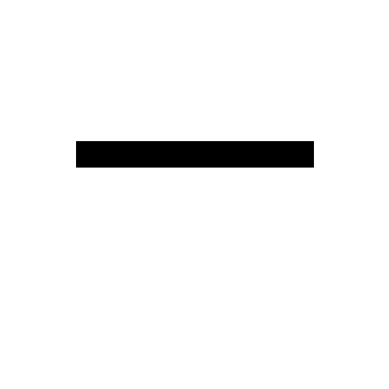

In [ ]:
canvas = np.zeros((280, 280, 4), dtype="uint8")
canvas[100:120, 50:230] = [0, 0, 0, 255]

gray = to_gray(canvas)
print("shape:", gray.shape)
print("background:", gray[0, 0], "| stroke:", gray[110, 100])

plt.imshow(gray, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.show()

In [ ]:
def get_strokes(gray, threshold=128):
    return ((gray < threshold) * 255).astype("uint8")

values in strokes: [  0 255]


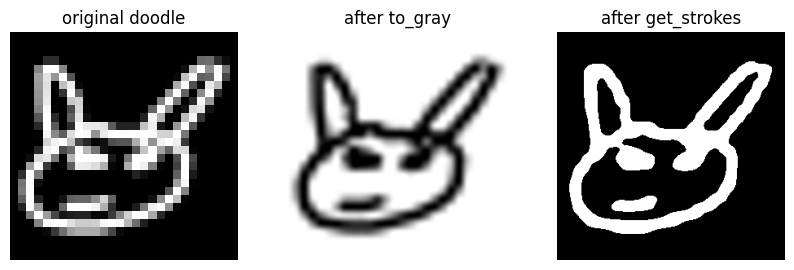

In [ ]:
data = np.load("data/subset.npz")

doodle = data["query_images"][0]

big = np.array(Image.fromarray(doodle).resize((280, 280), Image.BICUBIC))
canvas = np.zeros((280, 280, 4), dtype="uint8")
canvas[..., 3] = big

gray = to_gray(canvas)
strokes = get_strokes(gray)

print("values in strokes:", np.unique(strokes))   # [0 255]

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
axes[0].imshow(doodle, cmap="gray")
axes[0].set_title("original doodle")
axes[1].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("after to_gray")
axes[2].imshow(strokes, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("after get_strokes")
for ax in axes:
    ax.axis("off")
plt.show()

In [ ]:
def crop_square(strokes, margin=0.1):
    ys, xs = np.where(strokes > 0)
    if len(ys) == 0:
        return None

    cropped = strokes[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, w = cropped.shape

    side = max(h, w)
    pad = int(side * margin)
    out = np.zeros((side + 2 * pad, side + 2 * pad), dtype=strokes.dtype)
    top = (out.shape[0] - h) // 2
    left = (out.shape[1] - w) // 2
    out[top:top + h, left:left + w] = cropped
    return out

before: (280, 280) | after: (148, 148)


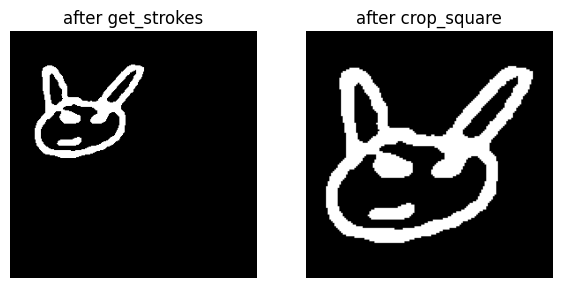

In [ ]:
big = np.array(Image.fromarray(doodle).resize((140, 140), Image.BICUBIC))
canvas = np.zeros((280, 280, 4), dtype="uint8")
canvas[20:160, 20:160, 3] = big

strokes = get_strokes(to_gray(canvas))
squared = crop_square(strokes)

print("before:", strokes.shape, "| after:", squared.shape)

fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
axes[0].imshow(strokes, cmap="gray")
axes[0].set_title("after get_strokes")
axes[1].imshow(squared, cmap="gray")
axes[1].set_title("after crop_square")
for ax in axes:
    ax.axis("off")
plt.show()

In [ ]:
def resize_28(squared):
    img = Image.fromarray(squared)
    out = np.array(img.resize((28, 28), Image.BOX))

    if out.max() < 230:
        size = max(3, (squared.shape[0] // 28) | 1)
        thick = img.filter(ImageFilter.MaxFilter(size))
        out = np.array(thick.resize((28, 28), Image.BOX))

    return (out.astype("float32") / out.max() * 255).astype("uint8")

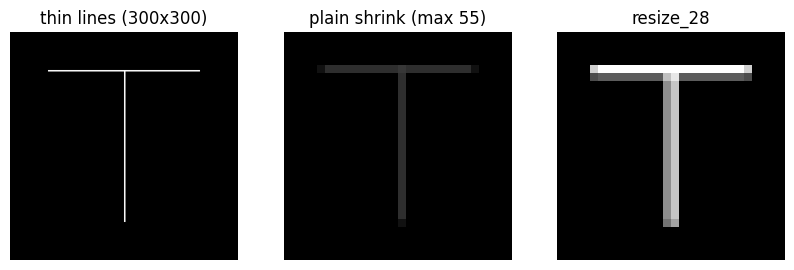

In [ ]:
thin = np.zeros((300, 300), dtype="uint8")
thin[50:250, 150:152] = 255
thin[50:52, 50:250] = 255

plain = np.array(Image.fromarray(thin).resize((28, 28), Image.BOX))
fixed = resize_28(thin)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
axes[0].imshow(thin, cmap="gray")
axes[0].set_title("thin lines (300x300)")
axes[1].imshow(plain, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"plain shrink (max {plain.max()})")
axes[2].imshow(fixed, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("resize_28")
for ax in axes:
    ax.axis("off")
plt.show()

In [ ]:
def preprocess_query(image, threshold=128):
    gray = to_gray(image)
    strokes = get_strokes(gray, threshold)
    squared = crop_square(strokes)
    if squared is None:
        return None
    return resize_28(squared)

In [ ]:
def search(query_vector, embeddings, k):

    query_vector = np.array(query_vector).flatten()

    scores = np.dot(embeddings, query_vector)

    sorted_indices = np.argsort(scores)[::-1]

    top_indices = sorted_indices[:k]

    top_scores = scores[top_indices]

    return top_indices, top_scores

In [ ]:
idx, scores = search(embeddings[0], embeddings, 5)

print("Top indices:", idx)
print("Similarity scores:", scores)

Top indices: [  0 154 103  41 101]
Similarity scores: [1.0000001  0.86158454 0.85294425 0.83660996 0.83613074]


In [ ]:
blank_canvas = np.zeros((280, 280, 4), dtype="uint8")
blank_paper = Image.new("RGB", (640, 480), (255, 255, 255))
print(preprocess_query(blank_canvas))
print(preprocess_query(blank_paper))

None
None


# Task four

In [ ]:
embeddings = np.load("index/embeddings.npy")
gallery_images = np.load("index/gallery_images.npy")

idx, scores = search(embeddings[0], embeddings, 5)
print("indices:", idx)
print("scores :", scores)

q = embed(model, data["query_images"][:1])
idx, scores = search(q, embeddings, 25)
print("top-25 scores, best to worst:", np.round(scores[[0, 1, 2, -1]], 3))

indices: [  0 154 103  41 101]
scores : [1.0000001  0.86158454 0.85294425 0.83660996 0.83613074]
top-25 scores, best to worst: [0.83  0.829 0.828 0.775]


In [ ]:
def evaluate_precision(query_embeddings, query_labels, embeddings, gallery_labels):

    precision_5 = []
    precision_25 = []

    for i in range(len(query_embeddings)):

        query = query_embeddings[i]
        label = query_labels[i]

        indices, scores = search(query, embeddings, 25)

        retrieved_labels = gallery_labels[indices]

        p5 = np.mean(retrieved_labels[:5] == label)

        p25 = np.mean(retrieved_labels[:25] == label)

        precision_5.append(p5)
        precision_25.append(p25)

    results = {
        5: np.mean(precision_5),
        25: np.mean(precision_25)
    }

    return results

In [ ]:
gallery_labels = np.load("index/gallery_labels.npy")
query_images = data["query_images"]
query_labels = data["query_labels"]

query_embeddings = embed(model, query_images)
print("query embeddings:", query_embeddings.shape)

results_model = evaluate_precision(query_embeddings, query_labels, embeddings, gallery_labels)
print(f"Your model   precision@5 = {results_model[5]:.3f} | precision@25 = {results_model[25]:.3f}")

query embeddings: (750, 1280)
Your model   precision@5 = 0.818 | precision@25 = 0.754


In [ ]:
def raw_pixel_vectors(images):

    vectors = images.reshape(len(images), -1)

    vectors = vectors.astype("float32")

    norms = np.linalg.norm(vectors, axis=1, keepdims=True)

    norms = np.maximum(norms, 1e-8)
    vectors = vectors / norms

    return vectors


raw_gallery = raw_pixel_vectors(gallery_images)
raw_queries = raw_pixel_vectors(query_images)

results_raw = evaluate_precision(
    raw_queries,
    query_labels,
    raw_gallery,
    gallery_labels
)

print("Raw Pixels Results")
print("Precision@5:", round(results_raw[5], 3))
print("Precision@25:", round(results_raw[25], 3))

Raw Pixels Results
Precision@5: 0.63
Precision@25: 0.529


In [ ]:
# Compare the two search methods
print("Search Engine Comparison")
print("------------------------")

print("Raw Pixels:")
print("Precision@5:", round(results_raw[5], 3))
print("Precision@25:", round(results_raw[25], 3))

print()

print("MobileNetV2:")
print("Precision@5:", round(results_model[5], 3))
print("Precision@25:", round(results_model[25], 3))

Search Engine Comparison
------------------------
Raw Pixels:
Precision@5: 0.63
Precision@25: 0.529

MobileNetV2:
Precision@5: 0.818
Precision@25: 0.754


In [ ]:
gallery_embeddings_inv = embed(
    model,
    gallery_images,
    invert=True
)

query_embeddings_inv = embed(
    model,
    query_images,
    invert=True
)

results_inv = evaluate_precision(
    query_embeddings_inv,
    query_labels,
    gallery_embeddings_inv,
    gallery_labels
)

print("Inverted Colors Results")
print("Precision@5:", round(results_inv[5], 3))
print("Precision@25:", round(results_inv[25], 3))

Inverted Colors Results
Precision@5: 0.828
Precision@25: 0.77


In [ ]:
# Display the final comparison results
print("Final Search Engine Results")
print("---------------------------")

print("1. Raw Pixels")
print("Precision@5:", round(results_raw[5], 3))
print("Precision@25:", round(results_raw[25], 3))

print()

print("2. MobileNetV2")
print("Precision@5:", round(results_model[5], 3))
print("Precision@25:", round(results_model[25], 3))

print()

print("3. MobileNetV2 with Inverted Colors")
print("Precision@5:", round(results_inv[5], 3))
print("Precision@25:", round(results_inv[25], 3))

Final Search Engine Results
---------------------------
1. Raw Pixels
Precision@5: 0.63
Precision@25: 0.529

2. MobileNetV2
Precision@5: 0.818
Precision@25: 0.754

3. MobileNetV2 with Inverted Colors
Precision@5: 0.828
Precision@25: 0.77


In [ ]:
gallery_features = embeddings
query_features = query_embeddings

heldout_images = data["heldout_images"]

heldout_features = embed(model, heldout_images)

in_scores = []

for query in query_features:
    indices, scores = search(query, gallery_features, 1)
    in_scores.append(scores[0])

in_scores = np.array(in_scores)

held_scores = []

for query in heldout_features:
    indices, scores = search(query, gallery_features, 1)
    held_scores.append(scores[0])

held_scores = np.array(held_scores)

print("Query Images")
print("Mean top-1 score:", round(in_scores.mean(), 3))
print("Number of images:", len(in_scores))

print()

print("Held-Out Images")
print("Mean top-1 score:", round(held_scores.mean(), 3))
print("Number of images:", len(held_scores))

Query Images
Mean top-1 score: 0.872
Number of images: 750

Held-Out Images
Mean top-1 score: 0.818
Number of images: 100


In [ ]:
import json

threshold = np.percentile(in_scores, 5)

config = {
    "threshold": round(float(threshold), 4),
    "top_k": 25,
    "invert": False
}

with open("index/config.json", "w") as file:
    json.dump(config, file)

print("Search Configuration")
print(config)

Search Configuration
{'threshold': 0.8012, 'top_k': 25, 'invert': False}


## For app

In [ ]:
import shutil
from google.colab import files

shutil.make_archive("index", "zip", "index")

files.download("index.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>